In [2]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
import tensorflow as tf
from keras.models import Sequential, save_model, load_model
from scipy.stats import kurtosis, skew
from scipy.fft import fft
from keras import Sequential
from keras.layers import LSTM, Dense, Dropout
from keras.utils import to_categorical
from sklearn.metrics import classification_report

In [3]:
data = pd.read_csv("C:/Users/Jeremy S Obozuwa/Desktop/fine_proj/sensor_data_with_datetime.csv",
				index_col='Datetime',
				parse_dates=True)
data.index.freq = 'MS'
data = pd.DataFrame(data)
data.head(10)

C:\Users\Jeremy S Obozuwa\AppData\Local\Temp\ipykernel_18812\1771431301.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  data = pd.read_csv("C:/Users/Jeremy S Obozuwa/Desktop/fine_proj/sensor_data_with_datetime.csv",


,accX,accY,accZ,temp,hum,sound,Condition
Datetime,,,,,,,
24-01-03,0.002948,0.023531,0.009803,37.148054,57.432655,58.657691,Normal Operation
24-02-03,-0.011497,-0.025450,-0.000161,39.350879,51.233515,59.605634,Normal Operation
24-03-03,-0.007224,0.001275,-0.000543,35.145646,47.151413,60.460505,Normal Operation
24-04-03,0.014186,-0.027624,-0.007712,40.141301,55.811067,61.201147,Normal Operation
24-05-03,-0.003707,-0.000604,-0.005018,42.379418,49.536603,61.562035,Normal Operation
24-06-03,0.008552,-0.007351,-0.007602,42.093990,48.403436,54.021806,Normal Operation
24-07-03,-0.025533,-0.010460,0.001912,43.163984,45.120651,56.472401,Normal Operation
24-08-03,0.022839,0.015501,0.011427,40.129649,53.642294,61.561650,Normal Operation
24-09-03,0.015260,0.017866,0.021621,41.218711,52.836003,61.350030,Normal Operation


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 140000 entries, 24-01-03 to 24-08-09
Data columns (total 7 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   accX       140000 non-null  float64
 1   accY       140000 non-null  float64
 2   accZ       140000 non-null  float64
 3   temp       140000 non-null  float64
 4   hum        140000 non-null  float64
 5   sound      140000 non-null  float64
 6   Condition  140000 non-null  object 
dtypes: float64(6), object(1)
memory usage: 8.5+ MB


In [5]:
interger = data[[i for i in data.columns if data[i].dtype in ['int64', 'float64']]]
interger.head()

,accX,accY,accZ,temp,hum,sound
Datetime,,,,,,
24-01-03,0.002948,0.023531,0.009803,37.148054,57.432655,58.657691
24-02-03,-0.011497,-0.025450,-0.000161,39.350879,51.233515,59.605634
24-03-03,-0.007224,0.001275,-0.000543,35.145646,47.151413,60.460505
24-04-03,0.014186,-0.027624,-0.007712,40.141301,55.811067,61.201147
24-05-03,-0.003707,-0.000604,-0.005018,42.379418,49.536603,61.562035


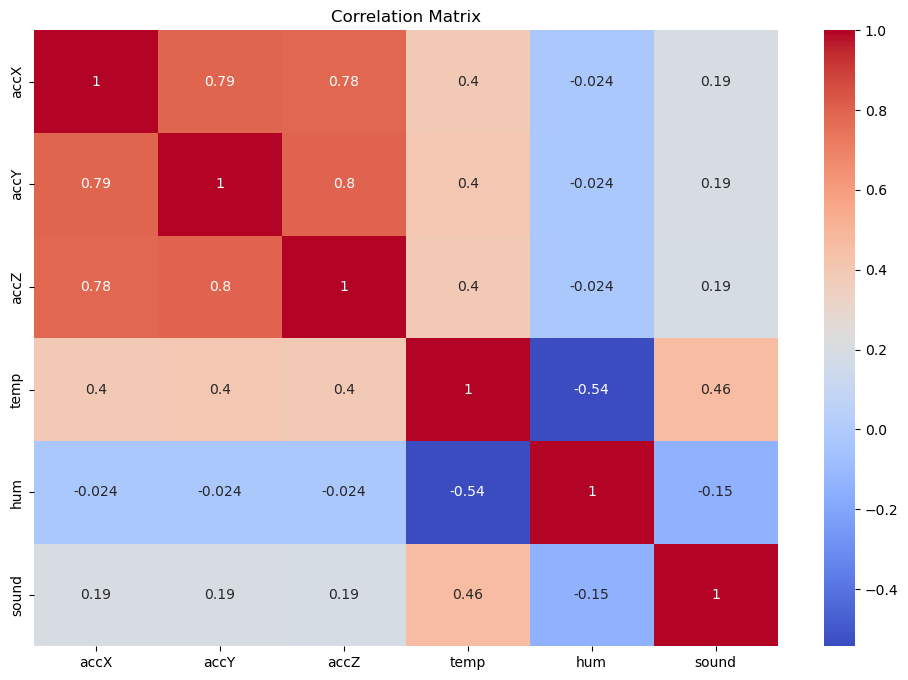

           accX      accY      accZ      temp       hum     sound
accX   1.000000  0.794218  0.783435  0.396274 -0.023537  0.192124
accY   0.794218  1.000000  0.795116  0.404543 -0.023968  0.194167
accZ   0.783435  0.795116  1.000000  0.396960 -0.023510  0.191989
temp   0.396274  0.404543  0.396960  1.000000 -0.543500  0.464572
hum   -0.023537 -0.023968 -0.023510 -0.543500  1.000000 -0.147058
sound  0.192124  0.194167  0.191989  0.464572 -0.147058  1.000000


In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

correlation_matrix = interger.corr()
plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()
print(correlation_matrix)

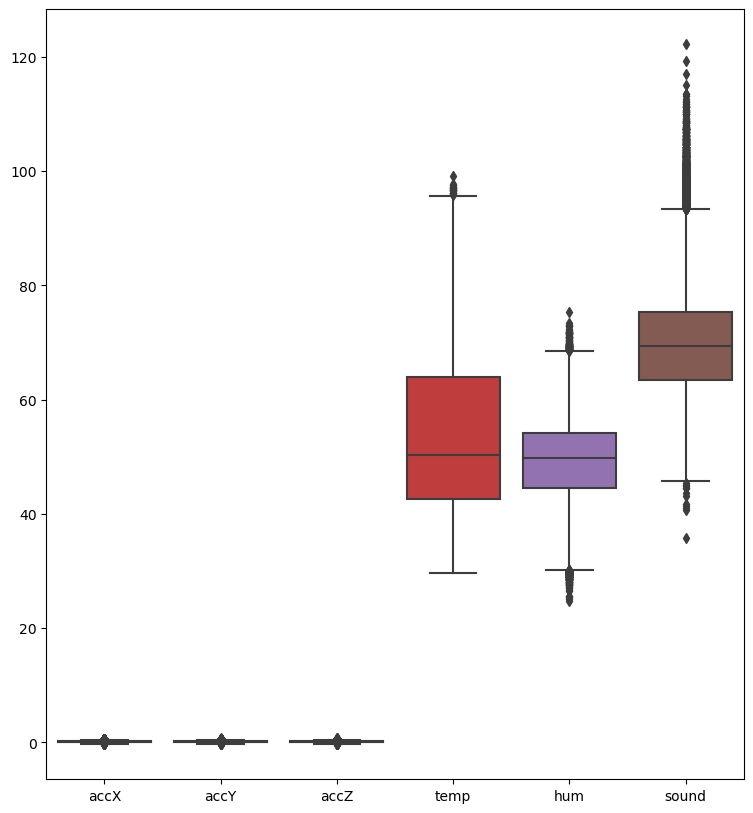

In [7]:
plt.figure(figsize=(9, 10))
sns.boxplot(interger)
plt.show()


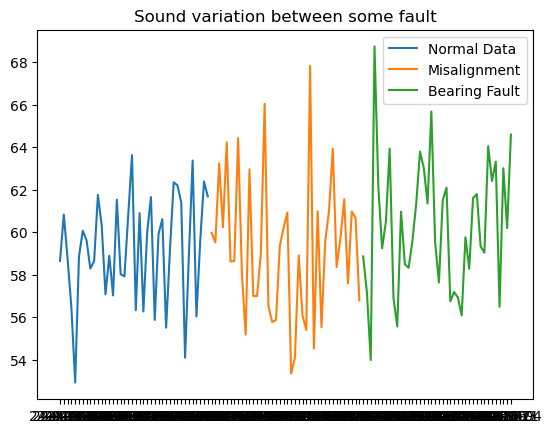

In [8]:
# Plot synthetic data
plt.title('Sound variation between some fault')
plt.plot(data.sound[:2000:50], label='Normal Data')
plt.plot(data.sound[2001:4000:50], label='Misalignment')
plt.plot(data.sound[4001:6000:50], label='Bearing Fault')
plt.legend()
plt.show()


In [9]:

# Define the fault types
fault_types = ["Normal Operation", "Misalignment", "Bearing Fault", "Imbalance",  
               "Overheating", "Lubrication Failure", "Electrical Fault"]

In [10]:

# Encode fault types (convert strings to integers)
encoder = LabelEncoder()
data['Condition'] = encoder.fit_transform(data['Condition'])

In [11]:
# Feature and target columns
features = ['accX', 'accY', 'accZ', 'temp', 'hum', 'sound', ]
target = 'Condition'

In [12]:
# Data Normalization
scaler = StandardScaler()
data[features] = scaler.fit_transform(data[features])

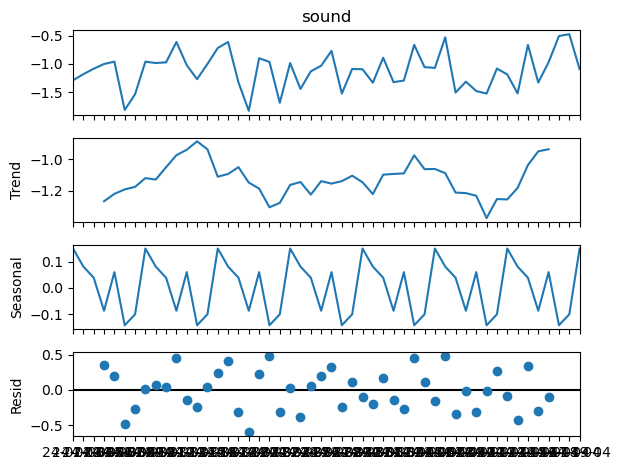

In [13]:
from statsmodels.tsa.seasonal import seasonal_decompose
import matplotlib.pyplot as plt

# Assuming your data is periodic, for example, a daily cycle with a period of 7 (weekly data)
results = seasonal_decompose(data['sound'].head(50), period=7)  # Manually set the period

# Plot the results
results.plot()
plt.show()


In [14]:
# Function to create sequences of 100 timesteps for LSTM
def create_sequences(data, features, target, sequence_length=100):
    X = []
    y_sensor = []
    y_fault = []
    
    for i in range(len(data) - sequence_length):
        X.append(data[features].iloc[i:i+sequence_length].values)
        y_sensor.append(data[features].iloc[i + sequence_length].values)  # Next timestep sensor values
        y_fault.append(data[target].iloc[i + sequence_length])  # Next timestep fault type
    
    return np.array(X), np.array(y_sensor), np.array(y_fault)

In [15]:
# Create sequences for LSTM
sequence_length = 100
X, y_sensor, y_fault = create_sequences(data, features, target, sequence_length)

In [22]:
y_fault[:5]

array([5, 5, 5, 5, 5])

In [16]:
# Split into training and test sets
X_train, X_test, y_sensor_train, y_sensor_test, y_fault_train, y_fault_test = train_test_split(
    X, y_sensor, y_fault, test_size=0.2, random_state=42
)

In [23]:
from keras.models import Model
from keras.layers import Input, LSTM, Dense, Dropout

# Assuming `features` is a list of feature names and `fault_types` is the list of fault categories

# Input shape based on your training data (sequence length, number of features)
input_shape = (X_train.shape[1], X_train.shape[2])

# Define the input layer
inputs = Input(shape=input_shape)

# LSTM layer
x = LSTM(128, return_sequences=False)(inputs)
x = Dropout(0.2)(x)
x = Dense(64, activation='relu')(x)

# Output layer for sensor values
sensor_output = Dense(len(features), activation='linear', name="sensor_output")(x)

# Output layer for fault type classification
fault_output = Dense(len(fault_types), activation='softmax', name="fault_output")(x)

# Define the model with two outputs
model = Model(inputs=inputs, outputs=[sensor_output, fault_output])

# Compile the model with two different losses and metrics
model.compile(optimizer='adam', 
              loss={'sensor_output': 'mse', 'fault_output': 'sparse_categorical_crossentropy'}, 
              metrics={'sensor_output': 'mae', 'fault_output': 'accuracy'})

# Print model summary to ensure input and output shapes are correct
model.summary()

Model: "functional_11"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 100, 6)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_2 (LSTM)       │ (None, 128)       │     69,120 │ input_layer_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 128)       │          0 │ lstm_2[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 64)        │      8,256 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sensor_output       │ (None, 6)         │        390 │ dense_2[0][0]     │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fault_output        │ (None, 7)         │        455 │ dense_2[0][0]     │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 78,221 (305.55 KB)

 Trainable params: 78,221 (305.55 KB)

 Non-trainable params: 0 (0.00 B)

In [24]:
# Train model
history = model.fit(X_train, {'sensor_output': y_sensor_train, 'fault_output': y_fault_train}, 
                    epochs=2, batch_size=32, validation_split=0.2)

Epoch 1/50
2798/2798 ━━━━━━━━━━━━━━━━━━━━ 380s 123ms/step - fault_output_accuracy: 0.9359 - loss: 0.5211 - sensor_output_mae: 0.4098 - val_fault_output_accuracy: 0.9999 - val_loss: 0.2980 - val_sensor_output_mae: 0.3744
Epoch 2/50
 563/2798 ━━━━━━━━━━━━━━━━━━━━ 3:05 83ms/step - fault_output_accuracy: 0.9817 - loss: 0.3573 - sensor_output_mae: 0.3799

: 

In [1]:
# Evaluate model
model.evaluate(X_test, {'sensor_output': y_sensor_test, 'fault_output': y_fault_test})


NameError: name 'model' is not defined

In [ ]:
# Predict future values and fault types
y_pred_sensor, y_pred_fault = model.predict(X_test)